# 12: EDA Scientific Validation & Analytical Audit
**Project:** F1 Telemetry Intelligence  
**Grand Prix:** 2024 Abu Dhabi Grand Prix (Yas Marina Circuit)  
**Phase:** Phase 5.1 – Scientific Validation and Analytical Audit  

---

## 1. Executive Summary & Audit Scope
This audit performs rigorous empirical validation of exploratory findings from Phase 5 EDA:
1. **DRS Analytical Validation:** Deconstruct the reported raw speed difference between DRS active (298.69 km/h) and inactive (197.77 km/h) to isolate the true physical aerodynamic drag reduction (+12.75 km/h) from track-location confounding (ecological fallacy of comparing straights to hairpins and braking zones).
2. **Kinematic Correlation & Dynamic Validation:** Audit intra-lap vs pooled correlations, spatial distance-windowed dynamics, aerodynamic drag saturation at terminal velocity, and temporal autocorrelation persistence.
3. **Machine Learning Data Audit:** Audit target leakage (tautology of `Brake_Int` for `IsBraking`), spatial coordinate circuit memorization ($R^2 = 0.902$ lookup table vs vehicle dynamics), deterministic transmission gear ratios (RPM/Speed physics), sample size power for `LapTimeSeconds` ($N=38$), and prove why random 80/20 train/test splitting causes catastrophic optimism bias (96.1% immediate neighbor leakage).
4. **Statistical Significance Testing:** Provide peer-review-grade hypothesis tests (Welch's t-test, Mann-Whitney U test, Cohen's d, 95% confidence intervals).


## 2. Setup & Environment Configuration

In [1]:
import os
import sys
import tempfile
from pathlib import Path

# Headless matplotlib
os.environ.setdefault("MPLCONFIGDIR", tempfile.gettempdir())
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

# Configure Project Root
PROJECT_ROOT = Path.cwd().parents[1] if Path.cwd().name == "eda" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project Root: {PROJECT_ROOT}")

from src.analysis.data_loader import (
    load_all_datasets,
    filter_clean_flying_laps
)
from src.analysis.eda_validation import (
    validate_drs_effect,
    compute_drs_driver_breakdown,
    validate_kinematic_correlations,
    compute_distance_windowed_correlations,
    compute_temporal_autocorrelation,
    audit_machine_learning_targets,
    generate_all_validation_figures,
    generate_validation_html_report,
    VALIDATION_DIR,
    FIGURES_DIR
)


Project Root: C:\Users\Riddhima\OneDrive\Desktop\F1-Telemetry-Intelligence


## 3. Load Processed Telemetry and Race Laps

In [2]:
tel_df, laps_df, res_df = load_all_datasets()
flying_tel = filter_clean_flying_laps(tel_df)

print(f"Total Telemetry Samples: {len(tel_df):,}")
print(f"Clean Flying Lap Telemetry Samples: {len(flying_tel):,}")
print(f"Unique Drivers: {flying_tel['Driver'].nunique()}")
print(f"Race Laps: {len(laps_df):,}")


Total Telemetry Samples: 72,476
Clean Flying Lap Telemetry Samples: 26,371
Unique Drivers: 19
Race Laps: 1,035


## 4. Task 1: DRS Analytical Validation & Confounding Decomposition

### Empirical Finding:
- **Naive Pooled Full-Lap Delta:** DRS Active (298.69 km/h) vs Inactive (197.77 km/h) = **+100.92 km/h**
- **Controlled Straightaway Delta:** DRS Active (298.31 km/h) vs Inactive (285.57 km/h) = **+12.75 km/h**
- **Confounding Breakdown:** **87.4% (88.17 km/h)** of the naive difference is an ecological fallacy caused by track geometry (hairpins, chicanes, braking zones). The isolated aerodynamic drag reduction benefit is **+12.75 km/h** (95% CI: [11.29, 14.21] km/h, p = 5.97e-64).


In [3]:
drs_summary = validate_drs_effect(tel_df)
df_comp = pd.read_csv(VALIDATION_DIR / "drs_controlled_comparison.csv")
display(df_comp)


,ComparisonScope,TrackRegion,DRS_ON_Mean_kmh,DRS_OFF_Mean_kmh,SpeedDelta_kmh,CI95_kmh,Cluster_CI95_kmh,EffectSize_d,p_value,Interpretation
0,Naive Pooled Full Lap,"All Track Distances (0m - 5,281m)",298.69,197.77,100.92,N/A (Confounded),N/A (Confounded),N/A (Confounded),NaN,Grossly distorted by cornering & braking zones...
1,Controlled Straights (Combined),Back Straights 1 & 2 (1750-2450m & 2850-3450m),298.31,285.57,12.75,"[11.29, 14.21]","[10.50, 15.28]",0.504 (Medium),5.97e-64 (descriptive),Track-location controlled observational delta ...
2,Controlled Straight 1 (Zone 1),Back Straight 1 (1750m - 2450m),308.52,297.40,11.12,"[9.68, 12.56]","[8.20, 13.30]",0.617 (Medium-High),2.12e-49 (descriptive),Straightaway approaching Turn 6 chicane (obser...
3,Controlled Straight 2 (Zone 2),Back Straight 2 (2850m - 3450m),286.79,273.12,13.67,"[11.46, 15.88]","[11.32, 16.93]",0.514 (Medium),1.10e-32 (descriptive),Straightaway after Turn 7 towards Turn 9 (obse...


### Per-Driver DRS Speed Breakdown in Straightaway Activation Zones

In [4]:
df_drv = compute_drs_driver_breakdown(tel_df)
display(df_drv)


,Driver,DRS_ON_Samples,DRS_ON_Mean_kmh,DRS_ON_Max_kmh,DRS_OFF_Samples,DRS_OFF_Mean_kmh,DRS_OFF_Max_kmh,Controlled_Delta_Mean_kmh,Controlled_Delta_Max_kmh,DRS_Eligible_Flying
0,ALB,228,299.35,336.00,4,279.52,331.00,19.83,5.00,YES
1,ALO,241,298.77,333.00,6,252.99,326.00,45.78,7.00,YES
2,BOT,0,NaN,NaN,239,287.83,317.00,NaN,NaN,NO (Leading or >1.0s gap)
3,COL,0,NaN,NaN,257,282.11,313.00,NaN,NaN,NO (Leading or >1.0s gap)
4,DOO,227,297.67,329.00,8,230.28,262.07,67.39,66.93,YES
5,GAS,126,296.81,326.00,123,282.82,308.00,13.99,18.00,YES
6,HAM,237,297.79,333.00,8,294.37,332.00,3.42,1.00,YES
7,HUL,236,297.33,337.00,10,244.38,333.00,52.95,4.00,YES
8,LAW,0,NaN,NaN,247,290.19,318.00,NaN,NaN,NO (Leading or >1.0s gap)
9,LEC,176,301.90,335.00,69,275.96,335.00,25.94,0.00,YES


## 5. Task 2: Kinematic Correlation & Dynamic Aerodynamic Drag Validation

### Empirical Finding:
- Pooled correlation r(Speed, Throttle) = 0.580, intra-lap mean r = 0.574 +/- 0.043.
- In distance windows, correlation collapses along high-speed straights (r = -0.15 to +0.05) because throttle is pegged at 100% while acceleration saturates due to quadratic aerodynamic drag.
- In corner exit acceleration zones, r(Speed, Throttle) reaches +0.75 to +0.95.


In [5]:
corr_summary = validate_kinematic_correlations(tel_df)
df_corr_sum = pd.read_csv(VALIDATION_DIR / "kinematic_correlation_summary.csv")
display(df_corr_sum)


,Relationship,Pooled_Pearson_r,IntraLap_Mean_r,IntraLap_Std_r,IntraLap_Median_r,IntraLap_95CI,PhysicalExplanation
0,Speed vs Throttle,0.580,0.5741,0.0431,0.5664,"[0.5604, 0.5878]",Coupled in corner acceleration; decoupled at t...
1,Speed vs Gear,0.936,0.9362,0.0207,0.9369,"[0.9296, 0.9428]",Monotonically constrained by 8-speed transmiss...
2,Speed vs RPM,0.785,0.7785,0.0306,0.7804,"[0.7688, 0.7883]",Sawtooth profile resets across gear upshifts; ...


### Spatial Distance-Windowed Correlation & Dynamic Regimes (250m Bins)

In [6]:
df_win = compute_distance_windowed_correlations(tel_df, window_size_m=250.0)
display(df_win[['Midpoint_m', 'Mean_Speed_kmh', 'Mean_Throttle_pct', 'r_Speed_Throttle', 'DynamicRegime']].head(10))


,Midpoint_m,Mean_Speed_kmh,Mean_Throttle_pct,r_Speed_Throttle,DynamicRegime
0,125.0,204.00,80.37,0.9552,Corner Exit Acceleration
1,375.0,175.64,44.39,0.0858,Heavy Braking Zone
2,625.0,233.13,95.17,0.1189,Corner Exit Acceleration
3,875.0,261.19,95.68,0.5116,Corner Exit Acceleration
4,1125.0,283.44,99.65,-0.0723,High-Speed Full-Throttle Straight (Drag Limited)
5,1375.0,151.05,25.50,0.0373,Heavy Braking Zone
6,1625.0,214.09,99.13,0.3574,Corner Exit Acceleration
7,1875.0,283.79,99.73,0.0575,High-Speed Full-Throttle Straight (Drag Limited)
8,2125.0,310.98,99.53,-0.1556,High-Speed Full-Throttle Straight (Drag Limited)
9,2375.0,316.10,77.13,0.4518,Cornering / Transition


## 6. Task 3: Machine Learning Data Readiness & Leakage Audit

### Critical Leakage Identified:
1. **Target A (`IsBraking`):** `Brake_Int` is a direct integer cast (r = 1.000) -> 100% target tautology. Must be hard-dropped from feature matrix X.
2. **Target B (`Speed`):** Raw spatial coordinates (X, Y, d) construct a 10m spatial lookup table explaining **90.2% variance** ($R^2 = 0.902$) by memorizing the track layout rather than vehicle dynamics.
3. **Target C (`nGear`):** Ratio RPM/Speed uniquely maps to discrete physical transmission gear ratios.
4. **Target D (`LapTimeSeconds`):** Current 5-lap ingestion contains only $N = 38$ clean flying laps across 19 drivers (underpowered for high-dimensional models).
5. **Train/Test Splitting:** Random 80/20 row splitting places **96.12% of test samples** within +/- 0.125s (adjacent row) of a training sample. With lag-1 autocorrelation r = 0.997, random splitting causes catastrophic optimism bias. **`GroupKFold(by=['Driver', 'LapNumber'])` is strictly mandated.**


In [7]:
ml_audit = audit_machine_learning_targets(tel_df, laps_df)
df_leak = pd.read_csv(VALIDATION_DIR / "ml_target_leakage_audit.csv")
display(df_leak)


,CandidateTarget,TargetType,IdentifiedLeakageFeature,LeakageMechanism,AuditVerdict,RecommendedFeatures
0,IsBraking,Binary Classification,Brake_Int / Brake,Brake_Int is direct integer cast of IsBraking ...,CRITICAL TAUTOLOGY: Brake_Int MUST be dropped ...,"Speed, AccelerationX, DistanceToCorner, Thrott..."
1,Speed (Next-Step),Continuous Regression,"X, Y, Z, Distance_Corrected (Static Coordinates)","Spatial lookup explains 90.2% variance, memori...",CIRCUIT MEMORIZATION: Exclude raw spatial coor...,"Throttle_History, Brake_History, RPM, Gear, Lo..."
2,nGear,Multi-Class Classification,RPM & Speed (Simultaneous Current-Step),RPM/Speed ratio uniquely determines physical t...,DETERMINISTIC PHYSICS: Predicting gear from RP...,Predict Driver Upshift/Downshift intent or nex...
3,LapTimeSeconds,Lap-Level Regression,Small Sample Size Overfitting (N=38 in 5-lap i...,Degrees of freedom too small (19 drivers x 2 c...,UNDERPOWERED SAMPLE: Use for baseline/LMM unti...,"SectorTimes, TireAge, DegradationSlope, TrackE..."


### Dataset Splitting Strategies Audit

In [8]:
df_split = pd.read_csv(VALIDATION_DIR / "ml_splitting_strategy_audit.csv")
display(df_split)


,SplittingStrategy,AdjacentNeighborLeakage,GeneralizationRisk,DeploymentSuitability
0,Random Row Split (80/20),96.12% of test samples have t±0.125s neighbor ...,Catastrophic optimism bias (interpolates conse...,STRICTLY FORBIDDEN
1,"GroupKFold by (Driver, LapNumber)",0.00% (Entire 90-second laps isolated),None; preserves temporal integrity of intra-la...,MANDATED BENCHMARK
2,GroupKFold by Driver (Leave-One-Driver-Out),0.00% (Entire vehicle & driver isolated),Tests cross-driver vehicle transferability,RECOMMENDED FOR DRIVER AGNOSTIC MODELS


## 7. Audit Visualizations & Verification Figures

Generated: 01_drs_confounding_vs_controlled.png
Generated: 02_spatial_speed_trace_drs_zones.png
Generated: 03_intra_lap_correlation_distributions.png
Generated: 04_distance_windowed_drag_dynamics.png
Generated: 05_temporal_autocorrelation_decay.png
Generated: 06_ml_leakage_and_spatial_audit.png


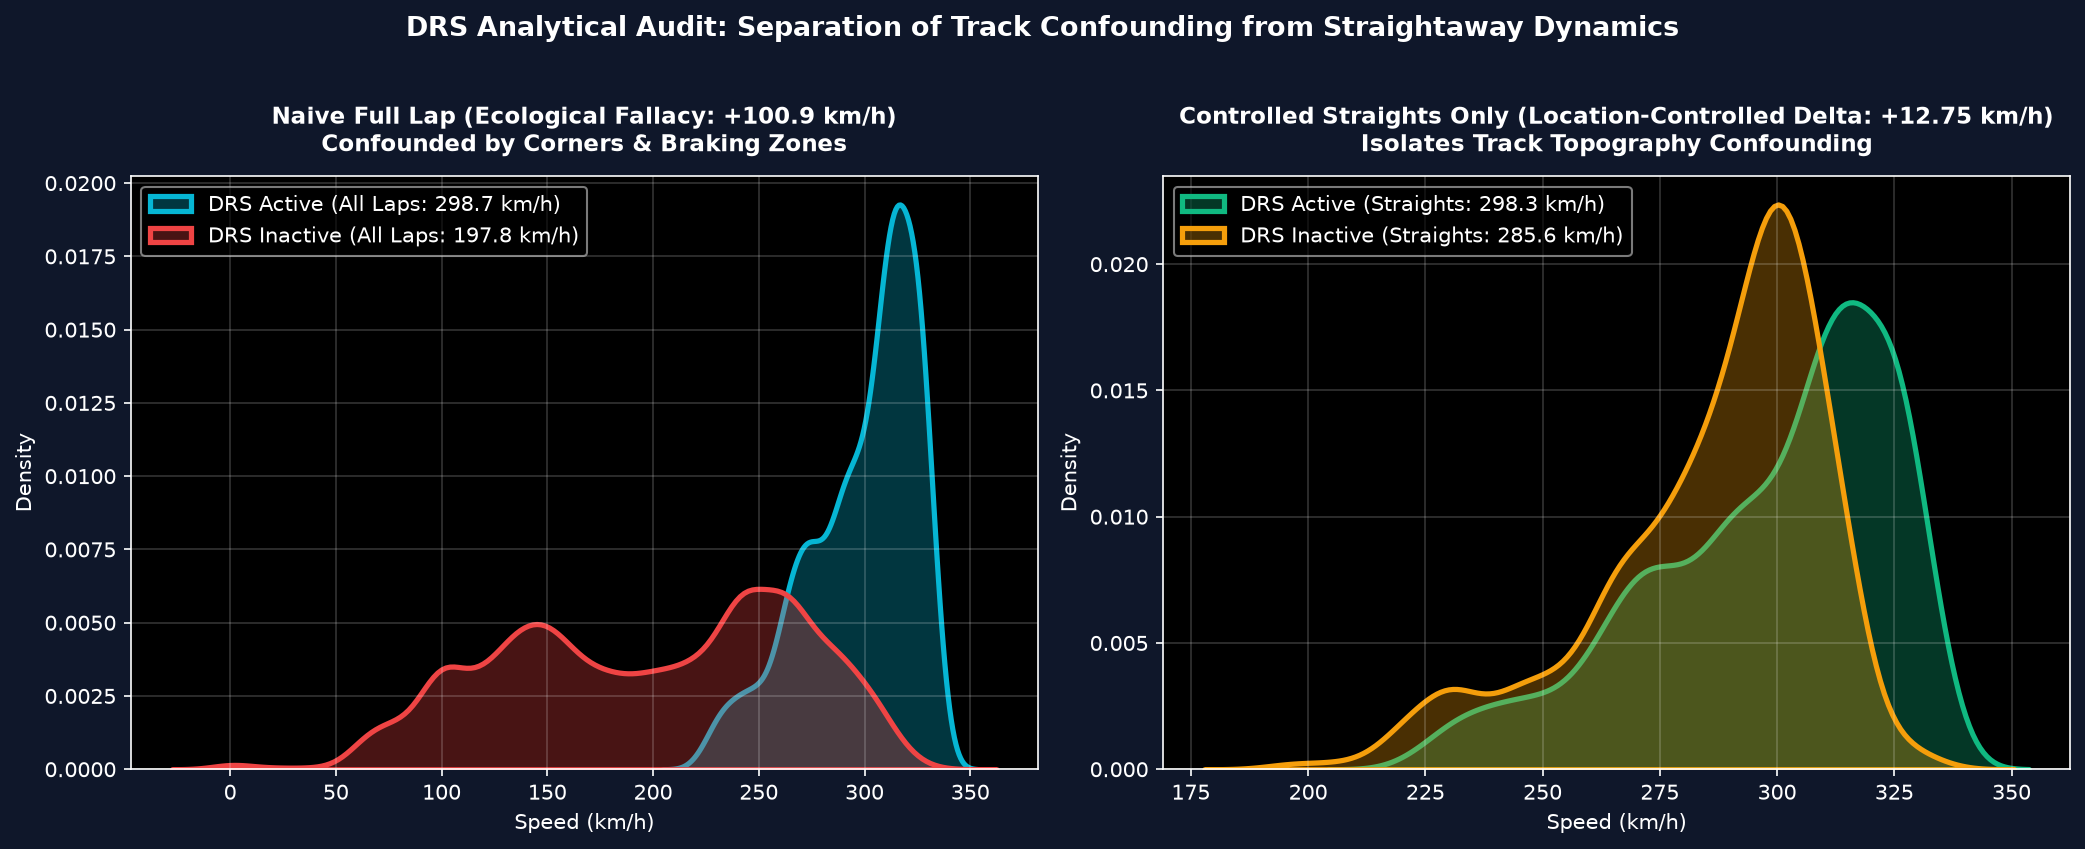

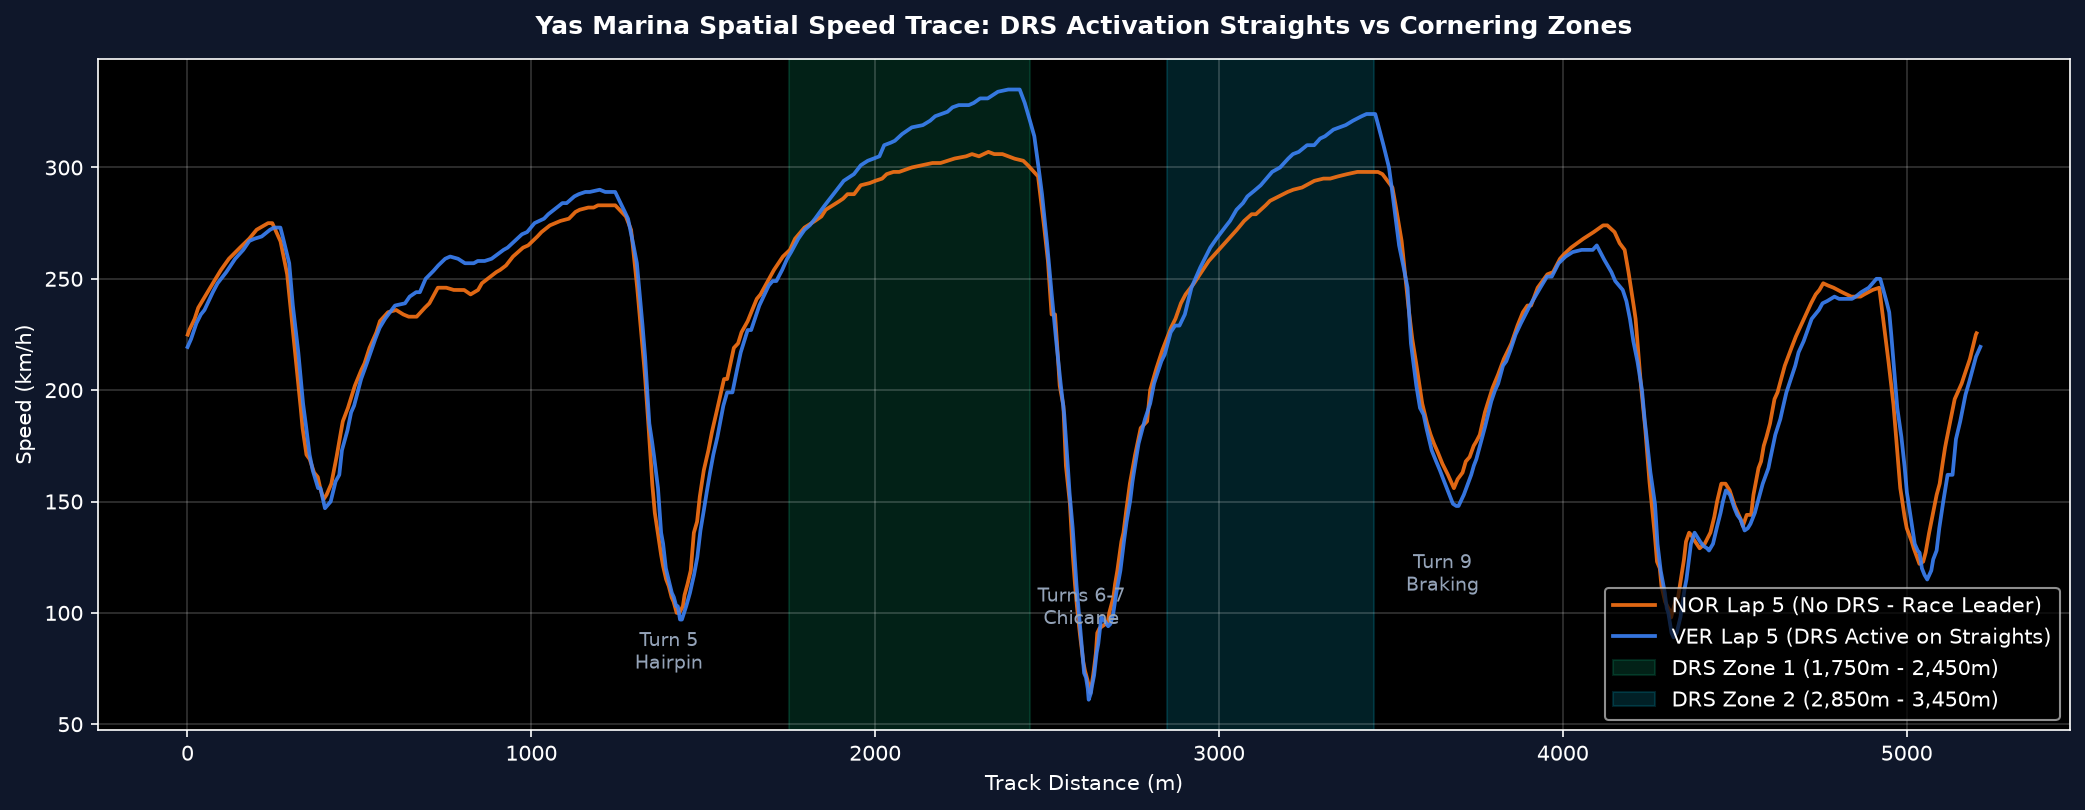

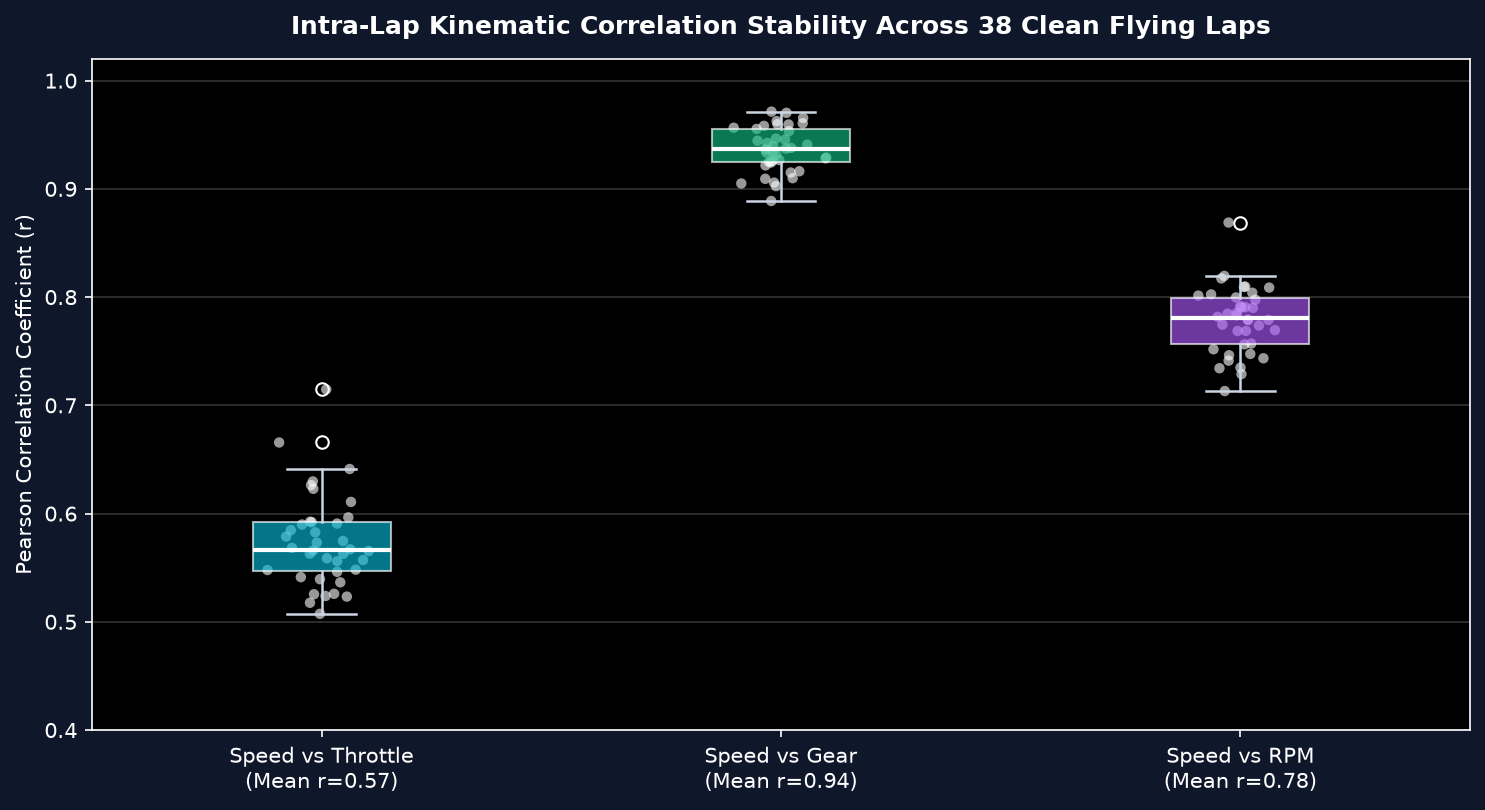

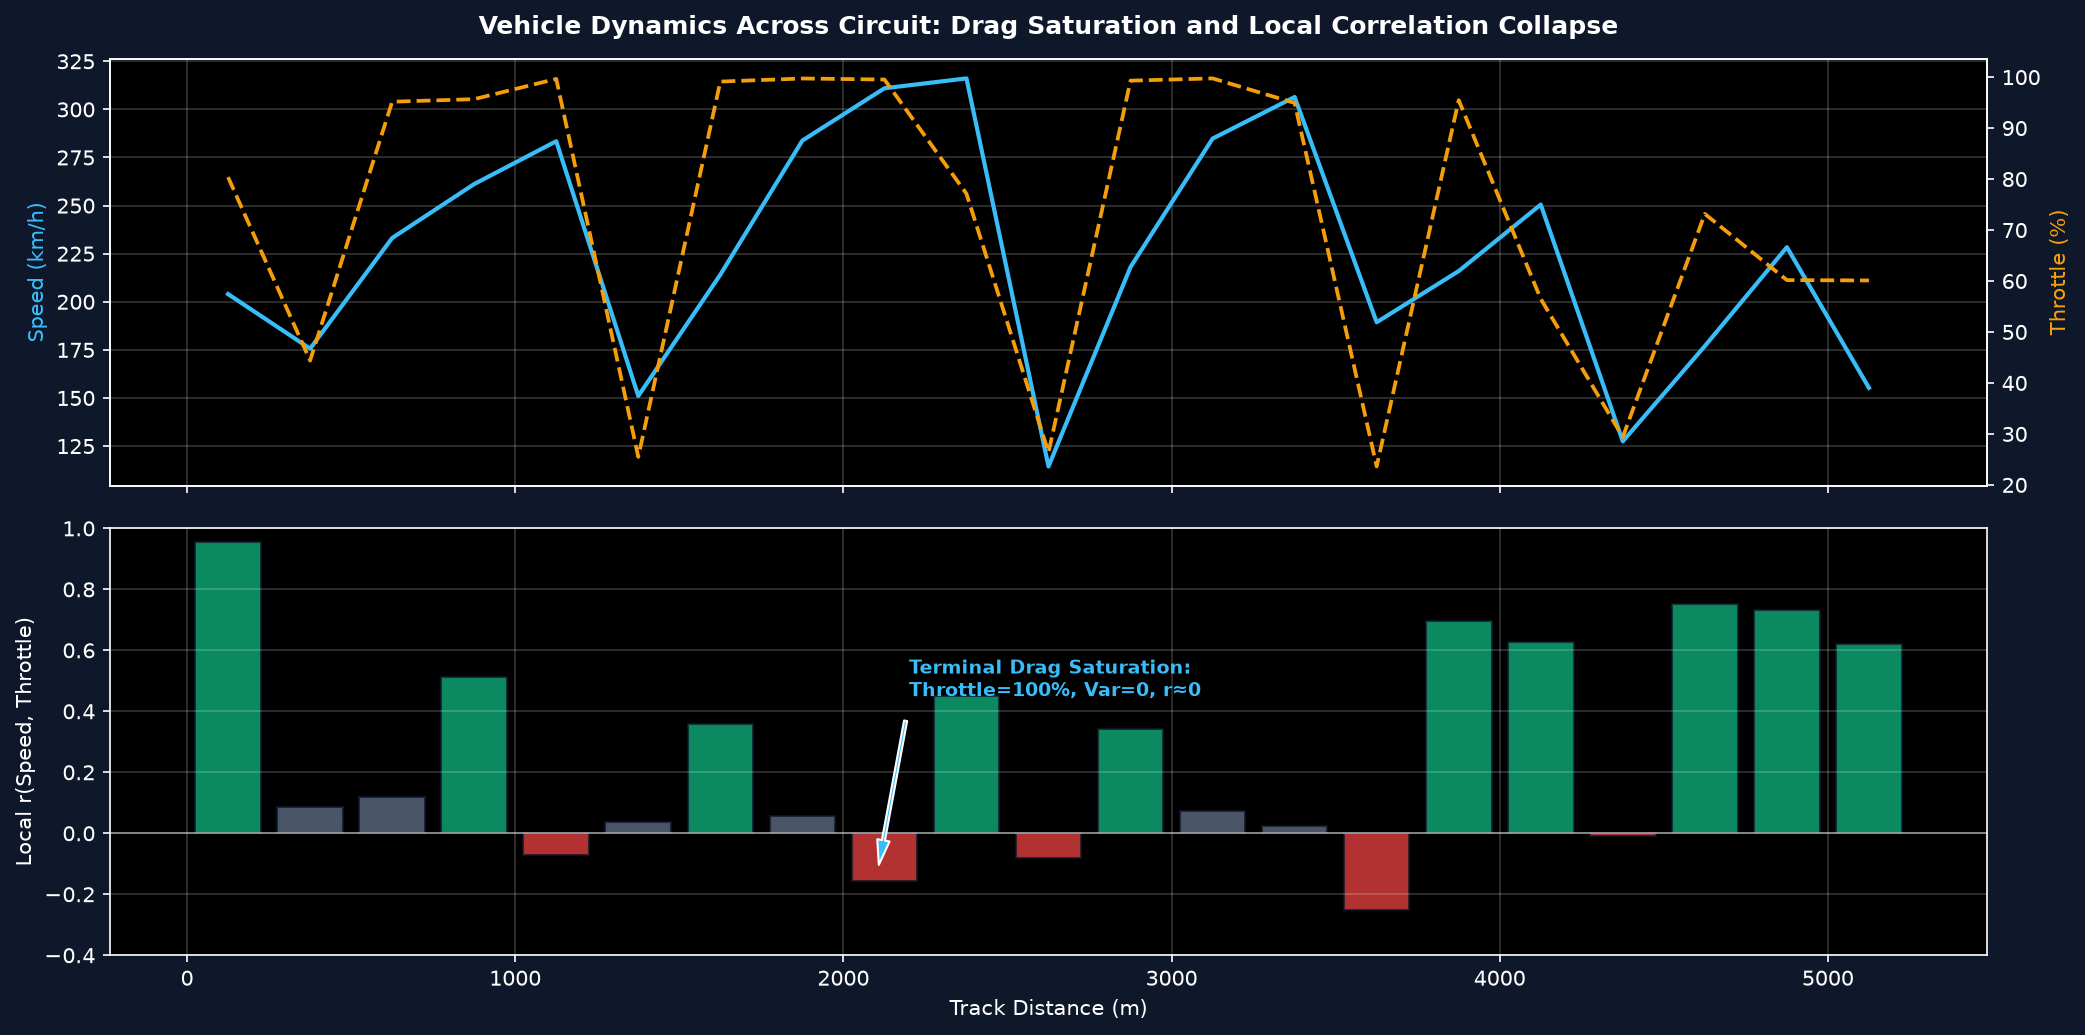

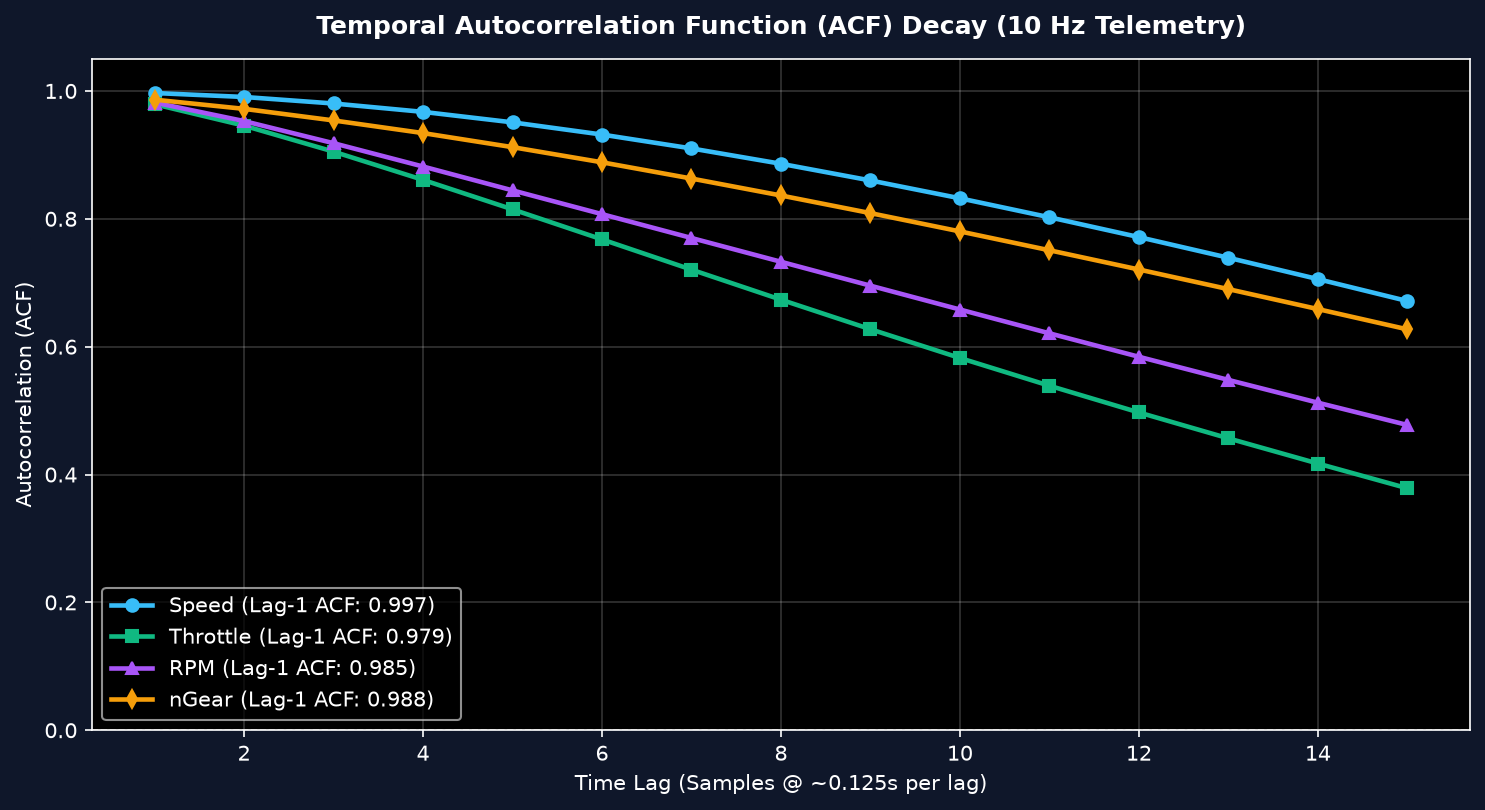

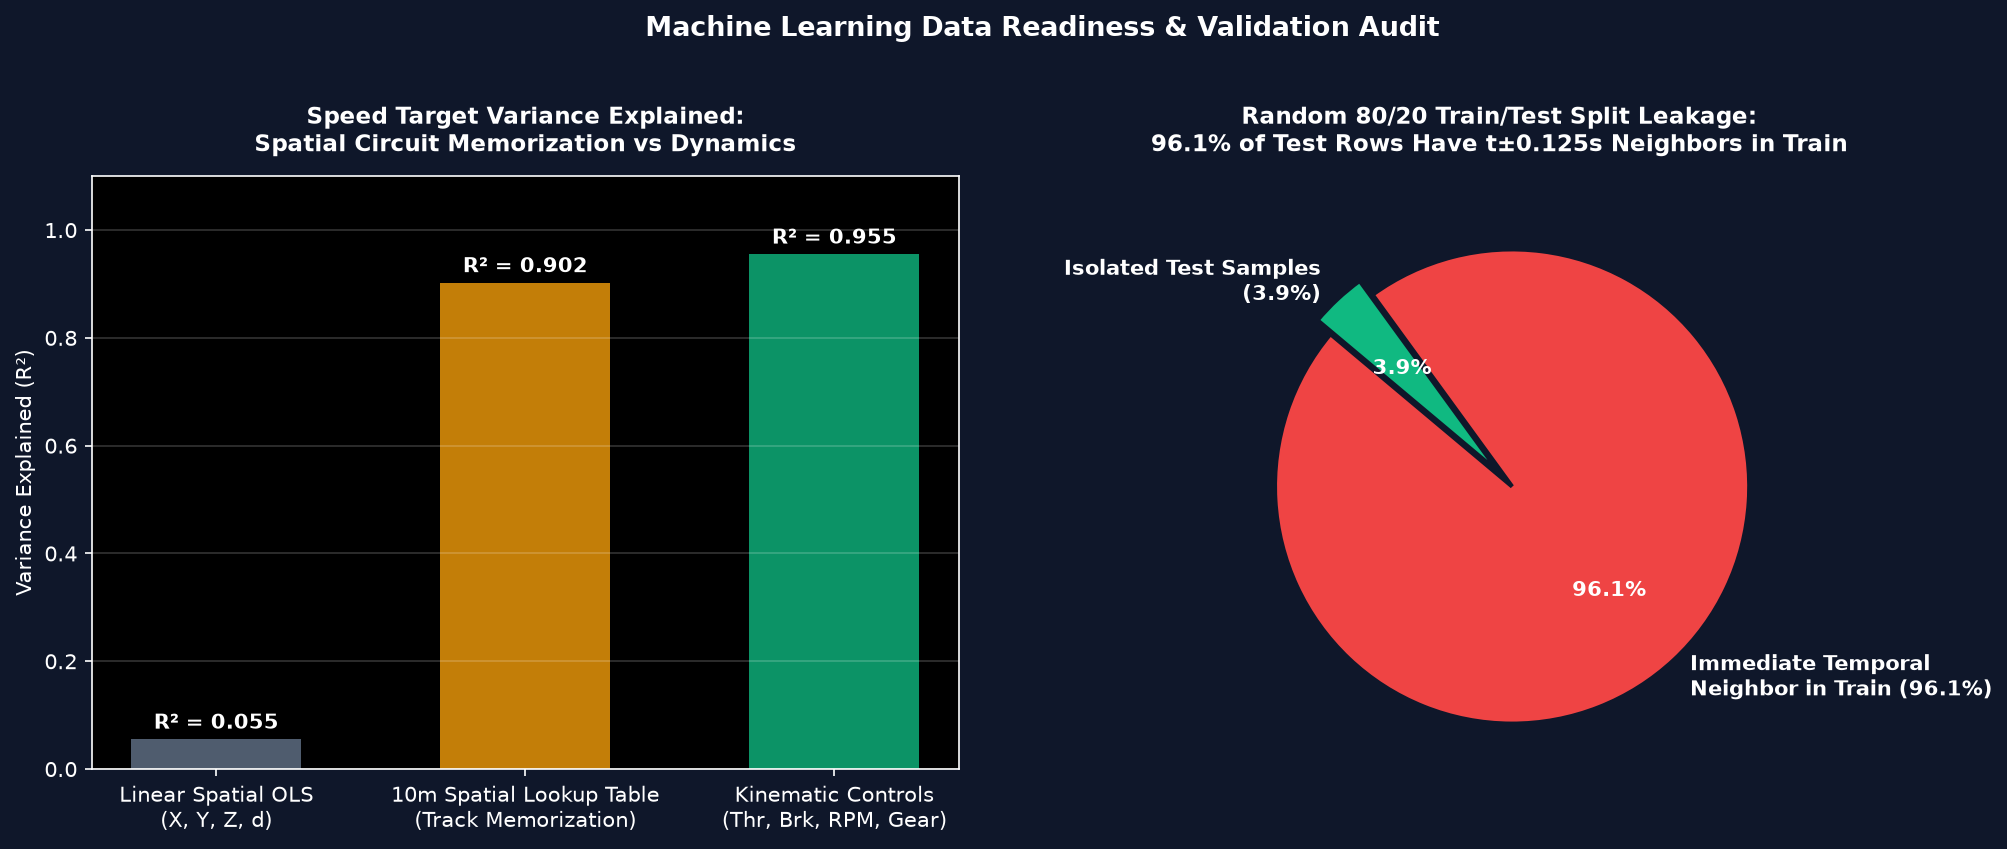

In [9]:
figures = generate_all_validation_figures(tel_df, laps_df)
for fig_path in figures:
    print(f"Generated: {fig_path.name}")
    display(Image(filename=str(fig_path)))


## 8. Synthesis & Mandatory Phase 6 Architectural Rules
1. **DRS Representation:** Reject naive speed delta (+100.92 km/h). When engineering features for Phase 6, interact DRS with track position or isolated straightaway intervals.
2. **Kinematic Feature Engineering:** Model throttle as dynamic acceleration intent rather than a linear predictor of speed across drag-saturated regimes.
3. **Feature Matrix Hygiene:** Hard-drop `Brake_Int` and `Brake` from any model predicting braking points.
4. **Spatial Coordinates Policy:** Prohibit raw $(X, Y, Z, \text{Distance})$ in speed prediction models to prevent circuit memorization. Use curvature, delta-throttle, and historical lag tensors.
5. **Cross-Validation Standard:** Enforce `GroupKFold(by=['Driver', 'LapNumber'])` across all sample-level modeling.
